# YOLOv8n — large, class/country-balanced dataset (notebook 09)

Final-iteration YOLO training run, on the new `RDD2022_4classes_large` dataset
(4,291 train / 597 val / 592 test) built to fix the two imbalances found in the
small/medium datasets:
- **class balance**: 1,100 images per class in train (vs. D00 outnumbering
  D20/D40 by 2-3x before), so the model is no longer weakest on the
  highest-severity classes (alligator crack, pothole).
- **country balance**: each class's quota is spread as evenly as possible
  across whichever countries actually contain it (Japan was ~46% of every
  previous processed dataset vs. ~28% of the raw pool; Czech Republic was
  nearly absent).

Same architecture/training philosophy as notebook 05 (YOLOv8n medium-dataset
retrain) so results are directly comparable across dataset-size iterations:
epochs=100 (max), patience=20, imgsz=640, batch=16. Batch size is unchanged
from notebook 05 -- a 1-epoch smoke test on this exact config measured **peak
GPU memory ~2.0GB** (of 8GB available) and **~51s/epoch**, so a full 100-epoch
run is ~85 minutes worst case, comfortably local-machine-friendly.

This is also the run that feeds **H1** (YOLOv8 mAP within 2% of Faster R-CNN,
with lower inference time) once the matching Faster R-CNN run on this same
dataset exists.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

DATA_YAML_PATH = Path("../data/processed/RDD2022_4classes_large/data.yaml")
DEVICE = 0  # GPU

## Training configuration

Matched to notebook 05 (YOLOv8n medium-dataset retrain) for a fair across-iteration comparison.

In [2]:
MODEL_PATH = "../yolov8n.pt"

EPOCHS = 100       # upper bound; early stopping should end this sooner if it converges
PATIENCE = 20      # stop if val metrics don't improve for 20 epochs
IMAGE_SIZE = 640
BATCH_SIZE = 16    # unchanged from notebook 05 -- smoke test showed ~2GB peak memory, huge headroom

PROJECT_DIR = "runs/road_damage_large"
RUN_NAME = "yolov8n_large_first_train"

print("Model path:", MODEL_PATH)
print("Epochs (max):", EPOCHS)
print("Patience:", PATIENCE)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)
print("Data YAML:", DATA_YAML_PATH)

Model path: ../yolov8n.pt
Epochs (max): 100
Patience: 20
Image size: 640
Batch size: 16
Device: 0
Data YAML: ..\data\processed\RDD2022_4classes_large\data.yaml


In [3]:
model = YOLO(MODEL_PATH)

## Training loop

In [4]:
train_results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.152 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.48  Python-3.10.20 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2070 with Max-Q Design, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=..\data\processed\RDD2022_4classes_large\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../yolov8n.pt,

## Test-set evaluation

In [5]:
RUN_DIR = model.trainer.save_dir  # actual save dir; project/name can be nested/suffixed by Ultralytics

best_model = YOLO(str(RUN_DIR / "weights" / "best.pt"))

test_metrics = best_model.val(
    data=str(DATA_YAML_PATH),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
)

Ultralytics 8.4.48  Python-3.10.20 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2070 with Max-Q Design, 8192MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 529.1679.0 MB/s, size: 348.9 KB)
val: Scanning C:\Users\vl4di\OneDrive - BUas\GitHub\Vladislav_Stoimenov_Graduation_Project_25_26\data\processed\RDD2022_4classes_large\test\labels... 592 images, 30 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 592/592 1.6Kit/s 0.4s
val: New cache created: C:\Users\vl4di\OneDrive - BUas\GitHub\Vladislav_Stoimenov_Graduation_Project_25_26\data\processed\RDD2022_4classes_large\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 4.9it/s 7.6s
                   all        592       1569      0.643      0.496      0.548        0.3
D00_Longitudinal_Crack        311        684      0.604      0.379      0.424      0.211
  D10_Transverse_Crack      

## Training history: loss curves, F1, mAP

Epochs run: 100 (max was 100, patience 20)
Best validation loss: 4.8400
Best validation F1-score: 0.5842
Best validation mAP@50: 0.5683
Best validation mAP@50:95: 0.3127


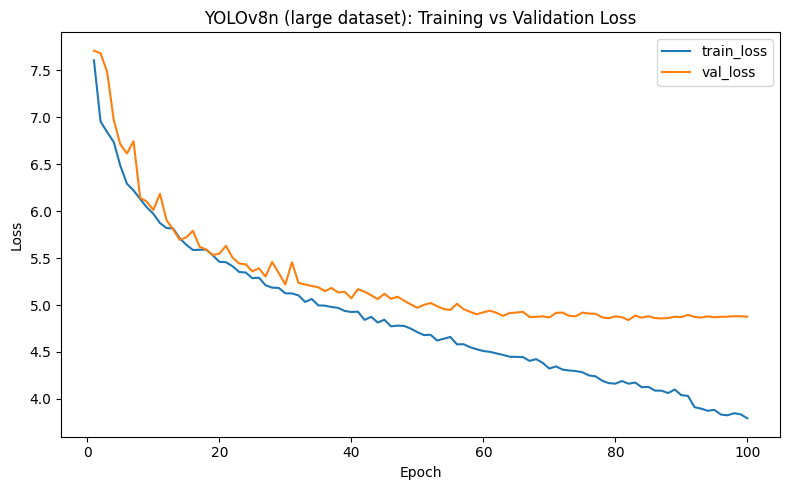

In [2]:
results_path = RUN_DIR / "results.csv"

results_df = pd.read_csv(results_path)
results_df.columns = results_df.columns.str.strip()

epochs = np.arange(1, len(results_df) + 1)

results_df["train_loss"] = (
    results_df["train/box_loss"] + results_df["train/cls_loss"] + results_df["train/dfl_loss"]
)
results_df["val_loss"] = (
    results_df["val/box_loss"] + results_df["val/cls_loss"] + results_df["val/dfl_loss"]
)
results_df["val_f1"] = (
    2 * results_df["metrics/precision(B)"] * results_df["metrics/recall(B)"]
    / (results_df["metrics/precision(B)"] + results_df["metrics/recall(B)"] + 1e-9)
)

print(f"Epochs run: {len(results_df)} (max was {EPOCHS}, patience {PATIENCE})")
print(f"Best validation loss: {results_df['val_loss'].min():.4f}")
print(f"Best validation F1-score: {results_df['val_f1'].max():.4f}")
print(f"Best validation mAP@50: {results_df['metrics/mAP50(B)'].max():.4f}")
print(f"Best validation mAP@50:95: {results_df['metrics/mAP50-95(B)'].max():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["train_loss"], label="train_loss")
plt.plot(epochs, results_df["val_loss"], label="val_loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv8n (large dataset): Training vs Validation Loss")
plt.tight_layout()
plt.savefig("large_loss_curve.png", bbox_inches="tight")
plt.show()

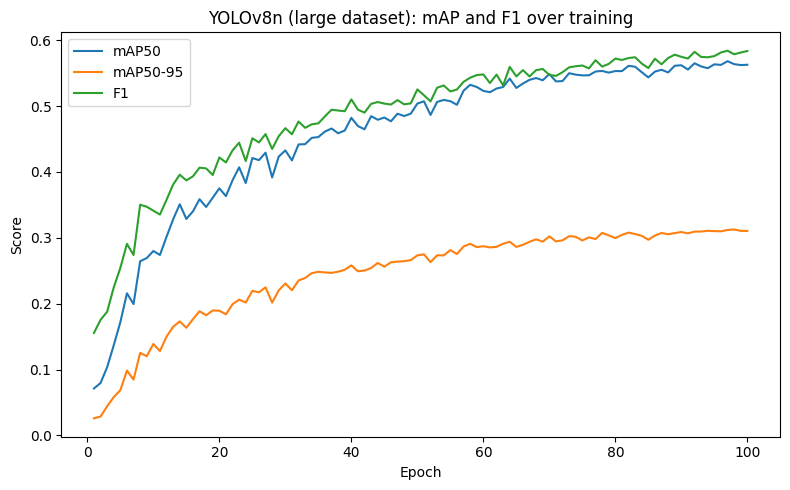

In [3]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["metrics/mAP50(B)"], label="mAP50")
plt.plot(epochs, results_df["metrics/mAP50-95(B)"], label="mAP50-95")
plt.plot(epochs, results_df["val_f1"], label="F1")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("YOLOv8n (large dataset): mAP and F1 over training")
plt.tight_layout()
plt.savefig("large_map_curve.png", bbox_inches="tight")
plt.show()

## Comparison across dataset-size iterations

Same architecture, same imgsz, growing dataset size and better class/country
balance -- isolates how much of the improvement (if any) comes from the data
changes alone.

In [8]:
comparison_df = pd.DataFrame([
    {
        "model": "YOLOv8n (small dataset, nb03)",
        "train_images": 277,
        "precision": 0.368, "recall": 0.305, "f1": 0.334,
        "mAP50": 0.297, "mAP50-95": 0.119,
    },
    {
        "model": "YOLOv8n (medium dataset, nb05)",
        "train_images": 1034,
        "precision": None, "recall": None, "f1": None,
        "mAP50": 0.424, "mAP50-95": 0.194,
    },
    {
        "model": "YOLOv8n (large dataset, nb09)",
        "train_images": 4291,
        "precision": round(float(test_metrics.box.mp), 3),
        "recall": round(float(test_metrics.box.mr), 3),
        "f1": round(2 * test_metrics.box.mp * test_metrics.box.mr / (test_metrics.box.mp + test_metrics.box.mr + 1e-9), 3),
        "mAP50": round(float(test_metrics.box.map50), 4),
        "mAP50-95": round(float(test_metrics.box.map), 4),
    },
])

comparison_df

,model,train_images,precision,recall,f1,mAP50,mAP50-95
0,"YOLOv8n (small dataset, nb03)",277,0.368,0.305,0.334,0.2970,0.1190
1,"YOLOv8n (medium dataset, nb05)",1034,NaN,NaN,NaN,0.4240,0.1940
2,"YOLOv8n (large dataset, nb09)",4291,0.643,0.496,0.560,0.5481,0.3002


## Notes

- This run feeds **H1** once matched against a Faster R-CNN run on the same
  `RDD2022_4classes_large` dataset (same imgsz, comparable effective batch) --
  see `src/training/fasterrcnn.py` and notebooks 07/08 for that model's
  training/eval code.
- Per-class metrics (`test_metrics.box.maps`, confusion matrix under
  `RUN_DIR`) are worth checking specifically for D20/D40 -- the two classes
  this dataset iteration was built to stop starving.
- Next planned step (per the project's iteration plan): fine-tune this model
  on the manually collected Sofia photos (`data/manual/`, ~160 images held
  back from a ~40-image test split) as a domain-adaptation stage, then
  re-evaluate against that held-out Sofia test set.